# Modelo de aplicação

Projeto CIN0144 · Tema 8: Praso — Previsão de Inadimplência.

**Objetivo**

Este notebook escolhe e treina o **modelo de aplicação**, que estima o risco do cliente no momento do cadastro.

Os candidatos são comparados em ROC-AUC. No fim, o modelo escolhido gera o **score de cada cliente**, que será usado em dois lugares:
- na política de crédito;
- na comparação com o modelo comportamental.

**Regras**
- Features e pré-processador: `fa.criar_features` e as 10 features de `fa.FEATURES_FINAIS`, definidas no notebook 03.
- Split e folds compartilhados (`src/split.py`): 80/20 com seed 42, estratificado por `inadimplente × tem_pedidos`, e validação cruzada 5 folds × 5 repetições no treino.
- **Toda escolha usa só o treino.**
- O teste é usado **uma vez só**, na seção 8, depois de todas as escolhas.
- Um modelo mais complexo só substitui um mais simples se ganhar mais de 1 erro padrão corrigido (`av.comparar`, correção de Nadeau e Bengio).
- Saídas só com agregados, nunca linhas de clientes (o repositório é público).

**Por que o split é estratificado**

O sorteio do split garante que o treino e o teste tenham:
- a mesma taxa de inadimplência (31,3%);
- a mesma fração de clientes com histórico de pedidos liberado (22%).

O segundo critério não muda nada para o modelo de aplicação. "Tem pedidos" nunca entra como feature dele, e a seção 10 confere isso.

Ele existe por causa do modelo comportamental. Os dois modelos são comparados nos clientes com histórico do mesmo teste (seções 8 e 9), e a estratificação garante que esse grupo tenha clientes suficientes para a comparação.

**Roteiro**

| Seção | Conteúdo |
|---|---|
| 1 | Configuração e dados |
| 2 | Linhas de base (do notebook 03) |
| 3 | Regressão logística |
| 4 | Busca de parâmetros: Random Forest, XGBoost e LightGBM |
| 5 | Comparação e escolha do modelo |
| 6 | Overfitting e categorias raras |
| 7 | Calibração |
| 8 | Avaliação final no teste |
| 9 | Score de cada cliente |
| 10 | Checagens |
| 11 | Resumo |

O código reutilizável fica em `src/modelo_aplicacao.py`:
- os modelos;
- o pré-processador da logística;
- a validação cruzada com predições fora da amostra;
- a calibração e os scores.

## 1. Configuração e dados

**Cache**

Este notebook treina ~110 configurações, cada uma nos 25 folds. Para não repetir esse trabalho, os resultados de `ma.validacao_cruzada` ficam guardados em `data/processed/cache_kan6/` (fora do git), com `joblib.Memory`.

Rodar o notebook de novo não retreina nada que já foi calculado com os mesmos dados e parâmetros.

Quando apagar o cache:
- se `ma.validacao_cruzada` mudar, ele se invalida sozinho;
- se mudar outra parte do `src/` (as features ou o pré-processador, por exemplo), apague a pasta à mão.

In [1]:
# Standard
import sys
import warnings
from pathlib import Path

# Manipulação de dados
import numpy as np
import pandas as pd

# Visualização
import matplotlib.pyplot as plt

# Modelagem
from sklearn.base import clone
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import make_pipeline

# Métricas e calibração (scikit-learn)
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve

# Cache das validações cruzadas
from joblib import Memory

# Módulos do projeto (src/)
sys.path.insert(0, str(Path.cwd().parent))
from src import avaliacao as av
from src import dados
from src import features_aplicacao as fa
from src import modelo_aplicacao as ma
from src import split as sp

# Exibição das tabelas e avisos
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", message="X does not have valid feature names")

# Gráficos: pasta das figuras e paleta da EDA
FIG = Path("../reports/figures")
AZUL, LARANJA, VERDE, CINZA, TEXTO = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA, "axes.labelcolor": TEXTO,
    "xtick.color": TEXTO, "ytick.color": TEXTO, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110,
})

# Cache das validações cruzadas (fora do git). Apague a pasta se mudar algo em src/ além de ma.validacao_cruzada.
memoria = Memory(dados.DIR_PROCESSED / "cache_kan6", verbose=0)
vc = memoria.cache(ma.validacao_cruzada)

In [2]:
clientes, pedidos = dados.carregar_dados_limpos()  # pedidos só para os folds e para o recorte da seção 8
if not sp.ARQ_SPLIT.exists():
    sp.salvar_split(sp.criar_split(clientes, pedidos))
split = sp.carregar_split()
assert split.equals(sp.criar_split(clientes, pedidos))  # o mesmo split da KAN-5
conjunto = clientes["id_cliente"].map(split)

X = fa.criar_features(clientes)
treino = clientes[conjunto == "treino"].reset_index(drop=True)
cv = sp.folds(treino, pedidos)
X_treino, y_treino = X[conjunto == "treino"], clientes.loc[conjunto == "treino", "inadimplente"]
print(f"treino: {len(X_treino)} clientes, {y_treino.mean():.1%} inadimplentes | {len(cv)} folds | "
      f"features: {', '.join(fa.FEATURES_FINAIS)}")

treino: 2400 clientes, 31.3% inadimplentes | 25 folds | features: idade_cnpj_ord, capital_social_ord, natureza, n_credores, socio_negativado, negativado_sem_credor, fonte_cliente, segmento_cliente, cnae_classe, regiao


A tabela de resultados de cada seção usa as mesmas colunas:

| Coluna | O que é |
|---|---|
| AUC validação | média do ROC-AUC nos 25 folds de validação: a medida de desempenho |
| erro padrão | erro padrão corrigido da média (Nadeau e Bengio), porque os folds reaproveitam clientes |
| AUC treino | média do ROC-AUC nos clientes usados para ajustar o modelo, em cada fold |
| treino − validação | quanto o modelo vai melhor nos clientes que viu do que nos que não viu: a medida de overfitting |

In [3]:
fator = np.sqrt(1 / len(cv) + len(cv[0][1]) / len(cv[0][0]))  # erro padrão corrigido (Nadeau e Bengio) = fator × desvio


def resumo(resultados: dict) -> pd.DataFrame:
    """AUC de validação (média e erro padrão corrigido), AUC de treino e a diferença entre os dois."""
    return pd.DataFrame({
        nome: {
            "AUC validação": r["auc_validacao"].mean(),
            "erro padrão": fator * r["auc_validacao"].std(ddof=1),
            "AUC treino": r["auc_treino"].mean(),
            "treino − validação": r["auc_treino"].mean() - r["auc_validacao"].mean(),
        }
        for nome, r in resultados.items()
    }).T

## 2. Linhas de base

São as três configurações do notebook 03 (features do modelo de aplicação), recalculadas com o mesmo código desta etapa:
- a idade do CNPJ sozinha;
- a árvore de decisão de profundidade 4;
- a Random Forest sem tuning.

A Random Forest é a referência que os modelos novos precisam superar. Nas tabelas de saída, ela aparece como `random forest (KAN-5)`.

In [4]:
so_idade = make_pipeline(fa.montar_preprocessador(["idade_cnpj_ord"]), clone(ma.random_forest()[-1]))
base = {
    "só idade (Random Forest)": vc(so_idade, X_treino, y_treino, cv),
    "árvore de decisão": vc(ma.arvore_decisao(), X_treino, y_treino, cv),
    "random forest (KAN-5)": vc(ma.random_forest(), X_treino, y_treino, cv),
}
resumo(base)

,AUC validação,erro padrão,AUC treino,treino − validação
só idade (Random Forest),0.631,0.011,0.656,0.024
árvore de decisão,0.723,0.014,0.748,0.025
random forest (KAN-5),0.772,0.013,0.829,0.056


**Leitura**

Os três números batem com o notebook 03 (0,631, 0,723 e 0,772). Esta etapa parte do mesmo ponto.

A Random Forest vai 0,056 melhor no treino do que na validação. Ela decora um pouco o treino, mas sem exagero (seção 6.1).

## 3. Regressão logística

A logística é o modelo mais simples e interpretável: cada feature tem um peso, e o score é a soma deles.

O limite dela é que só soma efeitos. A EDA mostrou que o risco vem de combinações: o peso do sócio negativado e o dos credores mudam com a idade do CNPJ (EDA, seção 6).

Por isso ela precisa de um pré-processador próprio (`ma.preprocessador_logistica`):

| Etapa | O que faz |
|---|---|
| Numéricas e binárias | padronizadas (média 0, desvio 1), para a regularização tratar todas igual |
| Categóricas | uma coluna 0/1 por categoria (*one-hot*); as raras (< 30 clientes no treino) dividem uma coluna só, como nas árvores |
| Interações (versão 2) | `idade × sócio negativado` e `idade × nº de credores`, as duas interações da EDA |

A regularização é L2. A força dela é escolhida numa grade de `C`: quanto menor o C, mais os coeficientes são encolhidos.

In [5]:
C_GRADE = [0.01, 0.03, 0.1, 0.3, 1, 3]
logisticas = {(c, inter): vc(ma.logistica(c, inter), X_treino, y_treino, cv) for inter in (False, True) for c in C_GRADE}
resumo({f"C = {c}" + (" + interações" if inter else ""): r for (c, inter), r in logisticas.items()})

,AUC validação,erro padrão,AUC treino,treino − validação
C = 0.01,0.759,0.013,0.767,0.008
C = 0.03,0.762,0.012,0.772,0.011
C = 0.1,0.761,0.012,0.776,0.014
C = 0.3,0.760,0.012,0.777,0.017
C = 1,0.759,0.011,0.777,0.018
C = 3,0.758,0.011,0.777,0.019
C = 0.01 + interações,0.758,0.013,0.766,0.008
C = 0.03 + interações,0.761,0.012,0.772,0.011
C = 0.1 + interações,0.761,0.012,0.776,0.014
C = 0.3 + interações,0.760,0.012,0.777,0.017


In [6]:
melhor_C = {inter: max(C_GRADE, key=lambda c: logisticas[(c, inter)]["auc_validacao"].mean()) for inter in (False, True)}
LOG = logisticas[(melhor_C[False], False)]
print("melhor C:", melhor_C[False], "(sem interações) e", melhor_C[True], "(com interações)")
pd.DataFrame([
    {"item": "interações (cada versão com o seu melhor C)",
     **av.comparar(logisticas[(melhor_C[True], True)]["auc_validacao"], LOG["auc_validacao"], cv)},
    {"item": "logística no lugar da random forest (KAN-5)",
     **av.comparar(LOG["auc_validacao"], base["random forest (KAN-5)"]["auc_validacao"], cv)},
]).set_index("item")

melhor C: 0.03 (sem interações) e 0.1 (com interações)


,ganho,erro padrão,ganho / erro padrão,veredito
item,,,,
interações (cada versão com o seu melhor C),-0.000,0.002,-0.241,neutro
logística no lugar da random forest (KAN-5),-0.011,0.004,-2.683,atrapalha


**Leitura**

**A regularização importa pouco.**
- De C = 0,01 a C = 3, o AUC fica entre 0,758 e 0,762.
- O melhor é C = 0,03, mais regularizado que o padrão do scikit-learn (C = 1).

**As interações da EDA não acrescentam nada** (ganho de 0,000, neutro).

Uma leitura possível: na EDA, os efeitos combinados aparecem fortes em grupos pequenos (ex: empresas de 1 a 3,5 anos com 2+ credores, n = 56). Um termo de produto muda o efeito de forma gradual, sem a forma desses degraus.

**A logística fica 0,011 abaixo da Random Forest** (0,762 contra 0,772; −2,7 erros padrão, "atrapalha").

O problema não é overfitting: ela quase não decora o treino (treino − validação de 0,011, contra 0,056 da Random Forest). As árvores ganham porque combinam as features sozinhas, o que a logística não faz.

**Decisão:** a logística sai da disputa pelo modelo final, mas fica como referência interpretável. Os coeficientes abaixo mostram para onde cada feature empurra o risco.

In [7]:
# Coeficientes da melhor logística, ajustada no treino inteiro. Numéricas padronizadas: efeito de +1 desvio padrão.
# Categóricas: efeito de estar na categoria (as raras dividem a coluna "infrequent_sklearn").
log_treino = ma.logistica(melhor_C[False]).fit(X_treino, y_treino)
coef = pd.Series(log_treino[-1].coef_[0], index=log_treino[0].get_feature_names_out())
pd.DataFrame({"coeficiente": coef, "razão de chances": np.exp(coef)}).sort_values(
    "coeficiente", key=abs, ascending=False).head(12)

,coeficiente,razão de chances
idade_cnpj_ord,-0.535,0.585
n_credores,0.449,1.567
socio_negativado,0.394,1.483
segmento_cliente_Segmento 18,-0.336,0.715
fonte_cliente_Fonte 1,-0.317,0.728
segmento_cliente_Segmento 16,-0.269,0.764
natureza_individual,0.258,1.294
segmento_cliente_Segmento 19,0.245,1.278
cnae_classe_infrequent_sklearn,0.244,1.276
natureza_ltda,-0.214,0.807


**Leitura**

Os sinais batem com a EDA.

A **razão de chances** é quanto a chance de inadimplência (p / (1 − p)) é multiplicada.

**Os maiores efeitos são de três features:**
- **idade do CNPJ:** +1 desvio padrão na faixa de idade multiplica a chance por 0,59;
- **número de credores:** ×1,57;
- **sócio negativado:** ×1,48 por desvio padrão. Como a feature é binária e foi padronizada, passar de 0 para 1 equivale a cerca de 2 desvios, ou ×2,2.

**Depois vêm o tipo de negócio e a origem do cliente:**
- os Segmentos 18 e 16 reduzem o risco, e o 19 e o 20 aumentam;
- a Fonte 1 reduz, e a Fonte 2 aumenta;
- o empresário individual aumenta, e a LTDA reduz.

As categorias são lidas umas contra as outras, porque o one-hot mantém todas.

**As classes raras do CNAE aumentam o risco** (×1,28). É o mesmo sinal dos 46,5% de inadimplência de quem fica fora das divisões principais (EDA 4.6).

## 4. Busca de parâmetros

Os três modelos de árvore usam o pré-processador do notebook 03, com as 10 features finais.

Para cada modelo, uma **busca aleatória** sorteia configurações de um espaço definido em `ma.ESPACOS` (seed 42) e mede cada uma nos 25 folds.

Os espaços favorecem modelos regularizados. Com 2.400 clientes no treino, árvores profundas e folhas pequenas decoram o treino.

| Modelo | O que a busca varia | Configurações |
|---|---|---|
| Random Forest | clientes por folha, features por divisão, profundidade | 20 (é ~8× mais lenta) |
| XGBoost | nº de árvores, taxa de aprendizado, profundidade, peso mínimo por folha, subamostragem de clientes e de features, regularização L2 | 40 |
| LightGBM | nº de árvores, taxa de aprendizado, nº de folhas, clientes por folha, subamostragem de clientes e de features, regularização L2 | 40 |

No LightGBM, as categóricas entram como códigos, como nas outras árvores. O tratamento nativo de categorias do LightGBM não é usado, porque tende a superajustar justamente nas categorias raras.

> **Cuidado com a escolha do melhor.**
>
> O AUC de cada configuração tem ruído. Escolher a melhor entre 40 tende a pegar uma que teve sorte, e o AUC dela sai otimista.
>
> Por isso a seção 5.1 confere a escolha em folds que não participaram dela.

In [8]:
N_ITER = {"random forest": 20, "xgboost": 40, "lightgbm": 40}  # a Random Forest é ~8× mais lenta
linhas = []
for m, espaco in ma.ESPACOS.items():
    for i, params in enumerate(ParameterSampler(espaco, N_ITER[m], random_state=sp.SEED)):
        r = vc(ma.FABRICAS[m](**params), X_treino, y_treino, cv)
        linhas.append({"modelo": m, "params": params, "auc_validacao": r["auc_validacao"], "auc_treino": r["auc_treino"]})
busca = pd.DataFrame(linhas)
busca["AUC validação"] = busca["auc_validacao"].map(np.mean)
busca["AUC treino"] = busca["auc_treino"].map(np.mean)
busca["treino − validação"] = busca["AUC treino"] - busca["AUC validação"]

# Quanto o AUC varia entre as configurações sorteadas
busca.groupby("modelo")["AUC validação"].describe()[["count", "min", "50%", "max"]].rename(
    columns={"count": "configurações", "50%": "mediana"})

,configurações,min,mediana,max
modelo,,,,
lightgbm,40.000,0.743,0.768,0.776
random forest,20.000,0.763,0.769,0.773
xgboost,40.000,0.750,0.770,0.777


In [9]:
# As 3 melhores configurações de cada modelo
top = busca.sort_values("AUC validação", ascending=False).groupby("modelo").head(3)
top[["modelo", "AUC validação", "AUC treino", "treino − validação", "params"]].set_index("modelo")

,AUC validação,AUC treino,treino − validação,params
modelo,,,,
xgboost,0.777,0.847,0.070,"{'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.6}"
lightgbm,0.776,0.852,0.077,"{'subsample_freq': 1, 'subsample': 0.6, 'reg_lambda': 10, 'num_leaves': 31, 'n_estimators': 500, 'min_child_samples': 10, 'learning_rate': 0.01, 'colsample_bytree': 0.6}"
xgboost,0.775,0.833,0.058,"{'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 100, 'min_child_weight': 10, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.6}"
xgboost,0.775,0.820,0.045,"{'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 0.6}"
lightgbm,0.775,0.832,0.058,"{'subsample_freq': 1, 'subsample': 0.8, 'reg_lambda': 5, 'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 50, 'learning_rate': 0.01, 'colsample_bytree': 0.8}"
lightgbm,0.774,0.812,0.038,"{'subsample_freq': 1, 'subsample': 0.8, 'reg_lambda': 10, 'num_leaves': 31, 'n_estimators': 100, 'min_child_samples': 100, 'learning_rate': 0.05, 'colsample_bytree': 0.6}"
random forest,0.773,0.831,0.058,"{'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 6}"
random forest,0.773,0.861,0.088,"{'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10}"
random forest,0.772,0.898,0.126,"{'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}"


**Leitura**

**Os três modelos chegam ao mesmo teto, perto de 0,776.**
- melhor XGBoost: 0,777;
- melhor LightGBM: 0,776;
- melhor Random Forest: 0,773, contra 0,772 da Random Forest sem tuning.

Com 2.400 clientes e 10 features fortes, o tuning tem pouco espaço para ganhar.

**Por que a busca aleatória basta**

Três modelos diferentes, com buscas separadas, chegaram praticamente ao mesmo AUC (0,773 a 0,777). Isso indica que o limite está nos dados e nas 10 features, e não no método de busca.

Dentro de cada busca, várias configurações já ficam coladas na melhor: no XGBoost, a segunda e a terceira dão 0,775, contra 0,777 da primeira (tabela acima).

Por isso, uma busca mais sofisticada, como a otimização bayesiana, dificilmente encontraria um modelo melhor. E testar mais configurações nos mesmos folds aumentaria o otimismo da escolha (seção 5.1).

**Os parâmetros pesam mais que a escolha do modelo.**
- Dentro do XGBoost, o AUC vai de 0,750 a 0,777.
- Dentro do LightGBM, vai de 0,743 a 0,776.

Uma configuração ruim perde até 0,03.

**As melhores configurações são regularizadas:**
- taxa de aprendizado baixa (0,01 a 0,05);
- subamostragem de features (60% a 80% por árvore);
- na Random Forest, folhas de 5 a 10 clientes com profundidade limitada (6 ou 10).

## 5. Comparação e escolha do modelo

Os candidatos são:
- as linhas de base;
- a melhor logística;
- a melhor configuração de cada modelo da busca.

Todos são comparados com a Random Forest sem tuning do notebook 03, nos mesmos 25 folds.

Pela regra, um candidato só substitui a Random Forest se o ganho passar de 1 erro padrão corrigido ("acrescenta").

In [10]:
melhor = busca.loc[busca.groupby("modelo")["AUC validação"].idxmax()].set_index("modelo")
REF = "random forest (KAN-5)"
candidatos = {
    "árvore de decisão": base["árvore de decisão"],
    "regressão logística": LOG,
    REF: base[REF],
    **{f"{m} (busca)": vc(ma.FABRICAS[m](**melhor.loc[m, "params"]), X_treino, y_treino, cv) for m in ma.ESPACOS},
}
ganhos = pd.DataFrame({
    nome: av.comparar(r["auc_validacao"], candidatos[REF]["auc_validacao"], cv)
    for nome, r in candidatos.items() if nome != REF
}).T[["ganho", "ganho / erro padrão", "veredito"]].add_suffix(" (vs. RF KAN-5)")
comparacao = resumo(candidatos).join(ganhos)
comparacao

,AUC validação,erro padrão,AUC treino,treino − validação,ganho (vs. RF KAN-5),ganho / erro padrão (vs. RF KAN-5),veredito (vs. RF KAN-5)
árvore de decisão,0.723,0.014,0.748,0.025,-0.049,-6.084,atrapalha
regressão logística,0.762,0.012,0.772,0.011,-0.011,-2.683,atrapalha
random forest (KAN-5),0.772,0.013,0.829,0.056,NaN,NaN,NaN
random forest (busca),0.773,0.013,0.831,0.058,0.001,0.518,neutro
xgboost (busca),0.777,0.012,0.847,0.070,0.004,1.437,acrescenta
lightgbm (busca),0.776,0.012,0.852,0.077,0.003,0.952,neutro


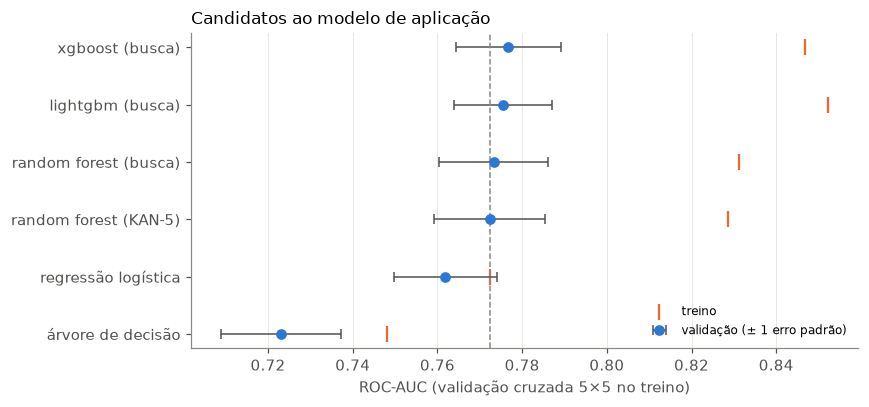

In [11]:
ordem = comparacao.sort_values("AUC validação").index
fig, ax = plt.subplots(figsize=(8, 3.8))
y_pos = np.arange(len(ordem))
ax.errorbar(comparacao.loc[ordem, "AUC validação"], y_pos, xerr=comparacao.loc[ordem, "erro padrão"],
            fmt="o", color=AZUL, ecolor=TEXTO, elinewidth=1, capsize=3, label="validação (± 1 erro padrão)")
ax.scatter(comparacao.loc[ordem, "AUC treino"], y_pos, marker="|", s=120, color=LARANJA, label="treino")
ax.axvline(comparacao.loc[REF, "AUC validação"], color=CINZA, ls="--", lw=1)
ax.set_yticks(y_pos, ordem)
ax.set_xlabel("ROC-AUC (validação cruzada 5×5 no treino)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title("Candidatos ao modelo de aplicação", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "kan6_comparacao.png", dpi=150); plt.show()

**Leitura**

**A árvore de decisão (−0,049) e a logística (−0,011) ficam abaixo** da Random Forest sem tuning, com veredito "atrapalha".

**A Random Forest com tuning (+0,001) e o LightGBM (+0,003) são neutros:** não ganham por mais de 1 erro padrão.

**O XGBoost é o único que "acrescenta":** +0,004 (1,4 erro padrão).

É um ganho pequeno, menor que a incerteza do AUC de cada modelo (~0,012). Mas é consistente: na comparação pareada, o XGBoost ganha da Random Forest em 19 dos 25 folds.

**Os modelos que validam melhor também decoram mais o treino** (marcas laranja). O XGBoost tem AUC de 0,847 no treino, contra 0,777 na validação. A seção 6.1 mostra que essa diferença não é um problema.

### 5.1 Conferência da escolha

**O problema**

A configuração vencedora de cada modelo foi escolhida pelo AUC nos mesmos 25 folds em que é comparada. Isso favorece quem teve sorte nesses folds.

**Como a conferência separa as duas coisas**
- a escolha usa só as repetições 1 e 2 dos folds (10 folds);
- o ganho sobre a Random Forest é medido nas repetições 3 a 5 (15 folds), que a escolha não olhou.

Os clientes são os mesmos, mas a divisão em folds é outra. Assim, a sorte da divisão não se repete.

In [12]:
# Escolha nas repetições 1 e 2 (folds 0 a 9); ganho medido nas repetições 3 a 5 (folds 10 a 24)
SEL, AVAL = slice(0, 10), slice(10, 25)
rf_kan5 = candidatos[REF]["auc_validacao"]
linhas = []
for m, grupo in busca.groupby("modelo", sort=False):
    pos = grupo["auc_validacao"].map(lambda a: a[SEL].mean()).idxmax()
    linhas.append({
        "modelo": m,
        "mesma configuração da busca nos 25 folds": grupo.loc[pos, "params"] == melhor.loc[m, "params"],
        "ganho na escolha (rep. 1–2)": grupo.loc[pos, "auc_validacao"][SEL].mean() - rf_kan5[SEL].mean(),
        **{f"{k} (rep. 3–5)": v for k, v in av.comparar(grupo.loc[pos, "auc_validacao"][AVAL], rf_kan5[AVAL], cv[AVAL]).items()},
    })
pd.DataFrame(linhas).set_index("modelo")

,mesma configuração da busca nos 25 folds,ganho na escolha (rep. 1–2),ganho (rep. 3–5),erro padrão (rep. 3–5),ganho / erro padrão (rep. 3–5),veredito (rep. 3–5)
modelo,,,,,,
random forest,True,0.001,0.001,0.002,0.411,neutro
xgboost,True,0.005,0.004,0.003,1.337,acrescenta
lightgbm,True,0.003,0.004,0.003,1.102,acrescenta


In [13]:
# Os dois boosters entre si
pd.Series(av.comparar(candidatos["xgboost (busca)"]["auc_validacao"], candidatos["lightgbm (busca)"]["auc_validacao"], cv),
          name="xgboost − lightgbm").to_frame()

,xgboost − lightgbm
ganho,0.001
erro padrão,0.001
ganho / erro padrão,0.912
veredito,neutro


**Leitura**

**A escolha se sustenta.**

Escolhendo só pelas repetições 1 e 2, a configuração vencedora de cada modelo é a mesma da busca nos 25 folds.

O ganho medido nas repetições 3 a 5 é praticamente o mesmo da escolha:
- XGBoost: +0,004 (1,34 erro padrão, "acrescenta");
- LightGBM: +0,004 (1,10);
- Random Forest: +0,001 (neutro).

O ganho dos boosters não é sorte dos folds em que eles foram escolhidos.

XGBoost e LightGBM empatam entre si (+0,001, neutro).

**Decisão: o modelo final é o XGBoost** (`ma.MODELO_FINAL` e `ma.PARAMS_FINAIS`).

Ele é o único que passa a regra nos dois testes: nos 25 folds e nas repetições 3 a 5. O LightGBM fica de fora só porque, nos 25 folds, o ganho dele (0,95 erro padrão) não chega a 1.

**Ressalva**

O ganho sobre a Random Forest sem tuning é pequeno (+0,004 de AUC). Na prática, os três modelos de árvore ordenam os clientes quase igual.

A conferência controla a sorte da divisão em folds, mas não a da amostra de clientes. A checagem independente é o teste (seção 8), que, por outro lado, não tem precisão para diferenças desse tamanho.

In [14]:
escolhido = ma.FABRICAS[ma.MODELO_FINAL](**ma.PARAMS_FINAIS)  # sem calibração
assert ma.MODELO_FINAL == "xgboost" and ma.PARAMS_FINAIS == melhor.loc["xgboost", "params"]
print("modelo final:", ma.MODELO_FINAL, ma.PARAMS_FINAIS)

modelo final: xgboost {'n_estimators': 500, 'learning_rate': 0.01, 'max_depth': 5, 'min_child_weight': 1, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_lambda': 10}


## 6. Overfitting e categorias raras

Três checagens:

1. **Treino × validação:** quanto cada modelo decora o treino, e se as configurações que decoram mais validam melhor.
2. **Categorias raras:** o pré-processador junta as categorias com menos de 30 clientes no treino num código só. Se o modelo superajustasse nelas, os clientes dessas categorias teriam AUC pior, ou um score médio longe da taxa observada.
3. **Corte das categorias raras:** o AUC muda se o corte for 10, 50 ou 100 clientes em vez de 30?

As checagens 2 e 3 usam o modelo final.

### 6.1 Treino × validação

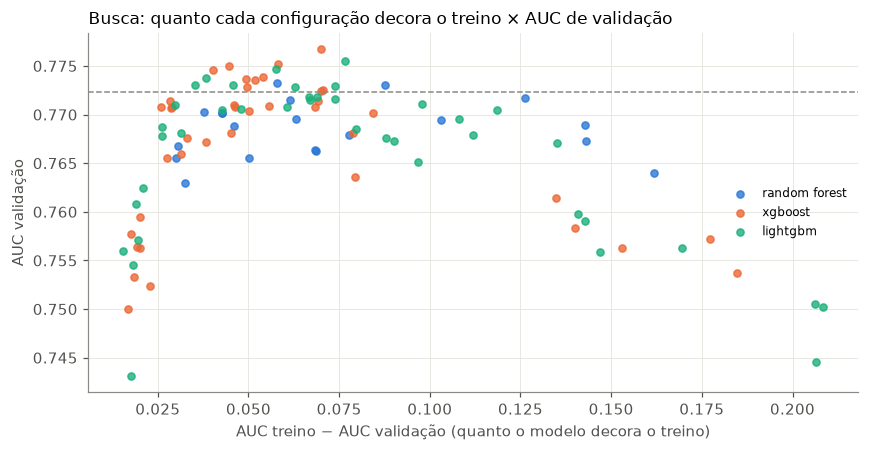

,configurações,média,máximo
treino − validação,,,
"até 0,03",21,0.761,0.771
"0,03 a 0,10",58,0.770,0.777
"acima de 0,10",21,0.761,0.772


In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for (m, grupo), cor in zip(busca.groupby("modelo", sort=False), [AZUL, LARANJA, VERDE]):
    ax.scatter(grupo["treino − validação"], grupo["AUC validação"], color=cor, s=22, alpha=0.8, label=m)
ax.axhline(comparacao.loc[REF, "AUC validação"], color=CINZA, ls="--", lw=1)
ax.set_xlabel("AUC treino − AUC validação (quanto o modelo decora o treino)")
ax.set_ylabel("AUC validação")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Busca: quanto cada configuração decora o treino × AUC de validação", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "kan6_overfitting.png", dpi=150); plt.show()

faixa = pd.cut(busca["treino − validação"], [0, 0.03, 0.10, 1], labels=["até 0,03", "0,03 a 0,10", "acima de 0,10"])
busca.groupby(faixa, observed=True)["AUC validação"].agg(configurações="size", média="mean", máximo="max").rename_axis(
    "treino − validação")

**Leitura**

O gráfico tem a forma de um **U invertido**, nos três modelos.

**À esquerda: quase não decoram o treino** (diferença até 0,03).
- São as configurações mais restritas: árvores rasas, poucas árvores, taxa de aprendizado baixa.
- Ficam em média em 0,761, por falta de capacidade (*underfitting*).

**À direita: decoram muito** (diferença acima de 0,10).
- São as de folhas pequenas, árvores profundas e taxa de aprendizado alta.
- Também perdem AUC, em média 0,761. É o overfitting.

**No meio: as melhores** (diferença de 0,03 a 0,10).
- A média é 0,770, e o máximo, 0,777.

**O modelo final tem diferença de 0,070**, no meio da faixa boa.

Ir 0,07 melhor no treino é normal num modelo de árvores. O que importa é que o AUC de validação dele é o melhor da busca, e que as configurações que decoram mais do que isso pioram.

### 6.2 Categorias raras

**Quem é "de categoria rara"**

Em cada fold, um cliente da validação é "de categoria rara" se tem alguma categoria (natureza, fonte, segmento ou classe do CNAE) com menos de 30 clientes no treino daquele fold.

O modelo nunca viu essa categoria com código próprio. Para ele, o cliente está no grupo das raras.

**O que a tabela mostra**

A tabela compara os dois grupos, fold a fold.

O score é o do modelo final calibrado (seção 7). Por isso, score médio e taxa observada podem ser comparados diretamente.

In [16]:
FINAL = vc(ma.modelo_final(), X_treino, y_treino, cv)  # modelo final calibrado, nos mesmos 25 folds
CAT_FINAIS = [c for c in fa.FEATURES_FINAIS if c in fa.CATEGORICAS]
y_arr = y_treino.to_numpy()


def em_categoria_rara(tr, va, colunas=CAT_FINAIS) -> np.ndarray:
    """Clientes da validação com alguma categoria que tem menos de fa.MIN_FREQ clientes no treino do fold."""
    rara = np.zeros(len(va), dtype=bool)
    for col in colunas:
        cont = X_treino[col].iloc[tr].value_counts()
        rara |= X_treino[col].iloc[va].map(cont).fillna(0).lt(fa.MIN_FREQ).to_numpy()
    return rara


linhas = []
for i, (tr, va) in enumerate(cv):
    rara, p, yv = em_categoria_rara(tr, va), FINAL["pred"][i, va], y_arr[va]
    for grupo, g in [("com alguma categoria rara", rara), ("só categorias frequentes", ~rara)]:
        linhas.append({"grupo": grupo, "clientes na validação": g.sum(), "AUC": roc_auc_score(yv[g], p[g]),
                       "taxa observada": yv[g].mean(), "score médio": p[g].mean()})
por_fold = pd.DataFrame(linhas)
tab = por_fold.groupby("grupo").mean()
tab["AUC: desvio entre folds"] = por_fold.groupby("grupo")["AUC"].std()
tab

,clientes na validação,AUC,taxa observada,score médio,AUC: desvio entre folds
grupo,,,,,
com alguma categoria rara,111.720,0.773,0.366,0.351,0.042
só categorias frequentes,368.280,0.777,0.297,0.304,0.028


In [17]:
# Por variável: clientes da validação na categoria rara daquela variável (os 25 folds juntos).
# O AUC só aparece com pelo menos 100 clientes distintos: abaixo disso, ele é ruído.
linhas = []
for col in CAT_FINAIS:
    y_g, p_g, ids = [], [], set()
    for i, (tr, va) in enumerate(cv):
        g = em_categoria_rara(tr, va, [col])
        y_g.append(y_arr[va][g]); p_g.append(FINAL["pred"][i, va][g]); ids |= set(va[g])
    y_g, p_g = np.concatenate(y_g), np.concatenate(p_g)
    if not len(ids):
        continue  # região: nenhuma das 3 categorias é rara
    linhas.append({"variável": col, "clientes distintos": len(ids), "taxa observada": y_g.mean(), "score médio": p_g.mean(),
                   "AUC": roc_auc_score(y_g, p_g) if len(ids) >= 100 else np.nan})
pd.DataFrame(linhas).set_index("variável")

,clientes distintos,taxa observada,score médio,AUC
variável,,,,
natureza,12,0.083,0.148,NaN
fonte_cliente,9,0.333,0.530,NaN
segmento_cliente,195,0.282,0.283,0.763
cnae_classe,428,0.400,0.375,0.764


**Leitura**

Não há sinal de overfitting nas categorias raras.

**O AUC é quase o mesmo nos dois grupos.**
- 0,773 nos clientes com alguma categoria rara (112 por fold, 23% da validação);
- 0,777 nos demais.

A diferença de 0,004 é pequena perto da variação entre folds (desvio de 0,042 no grupo raro, que é menor).

**O score médio acompanha a taxa observada.**
- grupo raro: 35,1% de score contra 36,6% observados;
- grupo frequente: 30,4% contra 29,7%.

Um modelo superajustado nas raras daria scores extremos para esses clientes. Aqui o erro é de 1,5 ponto e para baixo: o modelo é levemente conservador com eles.

**Por variável:**
- **classes raras do CNAE** (428 clientes distintos, 40% de inadimplência): score médio de 37,5% e AUC de 0,764;
- **segmentos raros** (195 clientes): score e taxa coincidem (28,3% e 28,2%);
- **natureza e fonte raras:** só 12 e 9 clientes (natureza "outros" e Fontes 3 e 4), o que não permite conclusão.

**Conclusão:** agrupar as raras funciona como esperado.

O grupo das classes raras do CNAE carrega o risco mais alto da EDA ("fora das divisões principais", 46,5%). O modelo usa esse grupo sem decorar classe a classe.

### 6.3 Corte das categorias raras

In [18]:
CORTES = [10, 30, 50, 100]
sens = {v: vc(clone(escolhido).set_params(columntransformer__cat__min_frequency=v), X_treino, y_treino, cv) for v in CORTES}
tab = resumo({f"< {v} clientes": r for v, r in sens.items()})
tab = tab.join(pd.DataFrame({f"< {v} clientes": av.comparar(r["auc_validacao"], sens[30]["auc_validacao"], cv)
                             for v, r in sens.items() if v != 30}).T[["ganho", "ganho / erro padrão", "veredito"]]
               .add_suffix(" (vs. 30)"))
tab

,AUC validação,erro padrão,AUC treino,treino − validação,ganho (vs. 30),ganho / erro padrão (vs. 30),veredito (vs. 30)
< 10 clientes,0.778,0.012,0.849,0.070,0.001,0.685,neutro
< 30 clientes,0.777,0.012,0.847,0.070,NaN,NaN,NaN
< 50 clientes,0.777,0.012,0.845,0.069,-0.000,-0.111,neutro
< 100 clientes,0.776,0.013,0.844,0.068,-0.000,-0.101,neutro


**Leitura**

O corte de 30 clientes não é crítico.
- Com 10, 50 ou 100 clientes, o AUC muda no máximo 0,001, sempre "neutro".
- A diferença treino − validação quase não muda (0,068 a 0,070).

O corte de 30 fica, por ser o da EDA e o do notebook 03.

## 7. Calibração

**Por que calibrar**

O AUC só mede a **ordem** dos clientes.

Mas a política de crédito vai ler o score como probabilidade ("este cliente tem 40% de chance de não pagar"), e o score do XGBoost não é uma probabilidade confiável.

**Como**

O modelo final passa por uma **calibração sigmoide** (`ma.calibrado`). É uma curva em S, ajustada com predições fora da amostra (5 folds internos), que converte o score em probabilidade.

Duas propriedades importantes:
- **A ordem não muda.** A curva é crescente, então a ordem dos clientes e o AUC continuam iguais (conferido abaixo, fold a fold).
- **É estável com poucos clientes.** A sigmoide tem só 2 parâmetros, o que a torna mais estável que a calibração isotônica.

**Como ler o gráfico**

O gráfico divide os clientes do treino em 10 grupos de mesmo tamanho, pelo score fora da amostra. Para cada grupo, compara o score médio com a taxa de inadimplência observada.

Um modelo calibrado fica na diagonal.

O **Brier** é o erro quadrático médio da probabilidade: quanto menor, melhor.

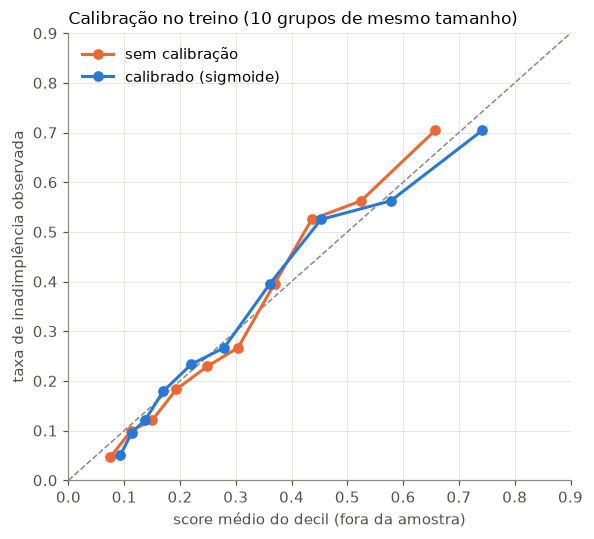

,Brier,score médio,taxa observada,score mín.,score máx.,AUC (média das 5 repetições)
sem calibração,0.172,0.307,0.313,0.044,0.835,0.778
calibrado,0.172,0.315,0.313,0.077,0.894,0.778


In [19]:
sem_cal = ma.score_fora_da_amostra(vc(escolhido, X_treino, y_treino, cv))
com_cal = ma.score_fora_da_amostra(FINAL)
assert np.allclose(FINAL["auc_validacao"], vc(escolhido, X_treino, y_treino, cv)["auc_validacao"])  # a ordem não muda

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=CINZA, ls="--", lw=1)
for score, nome, cor in [(sem_cal, "sem calibração", LARANJA), (com_cal, "calibrado (sigmoide)", AZUL)]:
    taxa, media = calibration_curve(y_treino, score, n_bins=10, strategy="quantile")
    ax.plot(media, taxa, marker="o", color=cor, lw=2, label=nome)
ax.set_xlabel("score médio do decil (fora da amostra)")
ax.set_ylabel("taxa de inadimplência observada")
ax.set_xlim(0, 0.9); ax.set_ylim(0, 0.9)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Calibração no treino (10 grupos de mesmo tamanho)", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "kan6_calibracao.png", dpi=150); plt.show()

pd.DataFrame({
    nome: {"Brier": brier_score_loss(y_treino, s), "score médio": s.mean(), "taxa observada": y_treino.mean(),
           "score mín.": s.min(), "score máx.": s.max(), "AUC (média das 5 repetições)": roc_auc_score(y_treino, s)}
    for nome, s in [("sem calibração", sem_cal), ("calibrado", com_cal)]
}).T

**Leitura**

**O XGBoost já sai quase calibrado.**
- O score médio fora da amostra é 30,7%, para uma taxa observada de 31,3%.
- As duas curvas seguem a diagonal.
- O Brier é o mesmo com e sem calibração (0,172).

**A calibração corrige os extremos.**

Sem ela, o modelo comprime a escala: o decil de maior risco tem score médio de ~66% e taxa observada de 70%.

O calibrado estica a escala (de 4%–84% para 8%–89%), um pouco além da conta no último decil (74% contra 70%).

**A ordem não muda:** o AUC é igual em todos os folds.

**Decisão:** a calibração fica no modelo final. Ela custa pouco e garante que o score possa ser lido como probabilidade, que é como a política de crédito vai usá-lo.

Nos decis do meio, as curvas oscilam em torno da diagonal. Com 240 clientes por decil, a taxa observada tem margem de erro de cerca de ±6 pontos.

## 8. Avaliação final no teste

**Como**

Com todas as escolhas feitas, o modelo final e as referências são ajustados no treino inteiro e avaliados **uma vez** nos 600 clientes do teste.

O intervalo de 95% vem de bootstrap: o teste é reamostrado 2.000 vezes.

A coluna "clientes com pedidos" é o recorte em que o modelo comportamental vai ser comparado com este.

**O que esperar**

Como o notebook 03 alertou, o erro padrão do AUC num teste de 600 clientes fica perto de 0,02.

O teste confirma a ordem de grandeza do desempenho, mas não separa modelos que diferem em 0,005.

In [20]:
# A partir daqui o teste é usado, uma vez só. Nenhuma escolha é feita com ele.
X_teste, y_teste = X[conjunto == "teste"], clientes.loc[conjunto == "teste", "inadimplente"]
FINAL_NOME = "xgboost (final, calibrado)"
modelos_teste = {
    "só idade (Random Forest)": so_idade,
    "árvore de decisão": ma.arvore_decisao(),
    "regressão logística": ma.logistica(melhor_C[False]),
    REF: ma.random_forest(),
    FINAL_NOME: ma.modelo_final(),
}
ajustados = {nome: clone(m).fit(X_treino, y_treino) for nome, m in modelos_teste.items()}
score_teste = {nome: m.predict_proba(X_teste)[:, 1] for nome, m in ajustados.items()}

tem_pedidos = clientes.loc[conjunto == "teste", "id_cliente"].isin(pedidos["id_cliente"]).to_numpy()
print(f"teste: {len(y_teste)} clientes, {int(y_teste.sum())} inadimplentes | com pedidos: {tem_pedidos.sum()} clientes, "
      f"{int(y_teste[tem_pedidos].sum())} inadimplentes")
resultado_teste = pd.concat({
    "teste inteiro": pd.DataFrame({n: ma.auc_bootstrap(y_teste, s) for n, s in score_teste.items()}).T,
    "clientes com pedidos": pd.DataFrame({n: ma.auc_bootstrap(y_teste[tem_pedidos], s[tem_pedidos])
                                          for n, s in score_teste.items()}).T,
}, axis=1)
auc_cv = {**resumo(base)["AUC validação"], **comparacao["AUC validação"], FINAL_NOME: FINAL["auc_validacao"].mean()}
resultado_teste[("validação cruzada", "AUC")] = [auc_cv[n] for n in resultado_teste.index]
resultado_teste

teste: 600 clientes, 188 inadimplentes | com pedidos: 133 clientes, 28 inadimplentes


teste inteiro               clientes com pedidos  \
                                     AUC IC inf IC sup                  AUC   
só idade (Random Forest)           0.659  0.612  0.704                0.627   
árvore de decisão                  0.746  0.702  0.786                0.642   
regressão logística                0.796  0.755  0.833                0.698   
random forest (KAN-5)              0.792  0.751  0.829                0.667   
xgboost (final, calibrado)         0.798  0.757  0.835                0.671   

                                         validação cruzada  
                           IC inf IC sup               AUC  
só idade (Random Forest)    0.502  0.745             0.631  
árvore de decisão           0.526  0.752             0.723  
regressão logística         0.577  0.801             0.762  
random forest (KAN-5)       0.551  0.772             0.772  
xgboost (final, calibrado)  0.550  0.775             0.777

In [21]:
# Diferença de AUC do modelo final para cada referência, nos mesmos 600 clientes (bootstrap pareado)
pd.DataFrame({f"final − {n}": ma.diferenca_bootstrap(y_teste, score_teste[FINAL_NOME], score_teste[n])
              for n in modelos_teste if n != FINAL_NOME}).T

,diferença,IC inf,IC sup
final − só idade (Random Forest),0.139,0.088,0.191
final − árvore de decisão,0.052,0.025,0.079
final − regressão logística,0.002,-0.016,0.020
final − random forest (KAN-5),0.006,-0.002,0.014


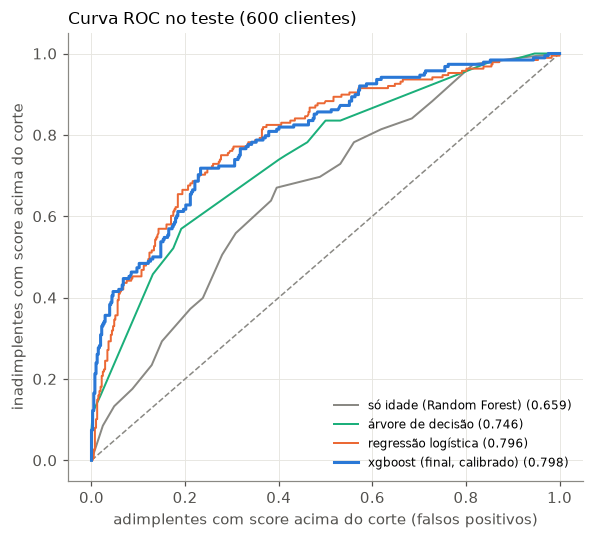

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=CINZA, ls="--", lw=1)
for nome, cor in [("só idade (Random Forest)", CINZA), ("árvore de decisão", VERDE), ("regressão logística", LARANJA),
                  (FINAL_NOME, AZUL)]:
    fpr, tpr, _ = roc_curve(y_teste, score_teste[nome])
    ax.plot(fpr, tpr, color=cor, lw=2 if nome == FINAL_NOME else 1.3,
            label=f"{nome} ({roc_auc_score(y_teste, score_teste[nome]):.3f})")
ax.set_xlabel("adimplentes com score acima do corte (falsos positivos)")
ax.set_ylabel("inadimplentes com score acima do corte")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Curva ROC no teste (600 clientes)", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "kan6_roc_teste.png", dpi=150); plt.show()

**Leitura**

**O modelo final tem AUC de 0,798 no teste** (IC de 95%: 0,757 a 0,835).

Fica acima da validação cruzada (0,777), mas todos os modelos sobem parecido:
- Random Forest: de 0,772 para 0,792;
- idade sozinha: de 0,631 para 0,659.

Este teste saiu um pouco mais fácil que a média dos folds, dentro do erro esperado para 600 clientes. Parte da subida também vem de os modelos serem ajustados com os 2.400 clientes do treino, e não com 1.920.

**O teste confirma a ordem nos extremos.** O modelo final ganha, com ICs longe de zero:
- da idade sozinha: +0,139;
- da árvore de decisão: +0,052.

**Entre os modelos fortes, o teste não separa.**
- contra a Random Forest: +0,006 (IC de −0,002 a +0,014);
- contra a logística: +0,002 (IC de −0,016 a +0,020), um empate.

Era o esperado: o teste não tem precisão para diferenças menores que ~0,02. A validação cruzada, mais precisa, coloca a logística 0,011 abaixo.

**Nos clientes com pedidos** (133 no teste, 28 inadimplentes), o AUC do modelo final é 0,671, com IC largo (0,550 a 0,775).

É a referência para o modelo comportamental, nos mesmos clientes e sempre com intervalo.

## 9. Score de cada cliente

Cada cliente recebe um score: a probabilidade calibrada de inadimplência.

**Treino (2.400 clientes)**

O score é fora da amostra: a média das 5 predições de validação do modelo final, uma por repetição dos folds.

Nenhum cliente recebe score de um modelo que o viu no ajuste. Por isso os scores do treino valem como os de um cliente novo, e servem para definir os cortes da política de crédito.

**Teste (600 clientes)**

O score vem do modelo final ajustado no treino inteiro (seção 8).

**Onde ficam**

O arquivo `data/processed/scores_aplicacao.csv` tem `id_cliente`, `conjunto` e `score`.

Ele fica **fora do git**, porque é um dado por cliente. Para ler: `ma.carregar_scores()`.

In [23]:
scores = pd.concat([
    pd.DataFrame({"id_cliente": clientes.loc[conjunto == "treino", "id_cliente"].to_numpy(), "conjunto": "treino",
                  "score": ma.score_fora_da_amostra(FINAL)}),
    pd.DataFrame({"id_cliente": clientes.loc[conjunto == "teste", "id_cliente"].to_numpy(), "conjunto": "teste",
                  "score": score_teste[FINAL_NOME]}),
]).sort_values("id_cliente").reset_index(drop=True)
ma.salvar_scores(scores)

alvo = scores["id_cliente"].map(clientes.set_index("id_cliente")["inadimplente"])
com_pedidos = scores["id_cliente"].isin(pedidos["id_cliente"])
grupos = {f"{c}{r}": (scores["conjunto"] == c) & m for c in ["treino", "teste"]
          for r, m in [("", True), (", com pedidos", com_pedidos)]}
pd.DataFrame({
    nome: {"clientes": int(g.sum()), "score médio": scores.loc[g, "score"].mean(), "taxa observada": alvo[g].mean(),
           "AUC": roc_auc_score(alvo[g], scores.loc[g, "score"])}
    for nome, g in grupos.items()
}).T

,clientes,score médio,taxa observada,AUC
treino,2400.000,0.315,0.313,0.778
"treino, com pedidos",531.000,0.283,0.207,0.693
teste,600.000,0.307,0.313,0.798
"teste, com pedidos",133.000,0.260,0.211,0.671


In [24]:
# Faixas de score: cortes nos decis do score do treino, aplicados aos dois conjuntos
cortes = np.quantile(scores.loc[scores["conjunto"] == "treino", "score"], np.linspace(0, 1, 11))
cortes[0], cortes[-1] = 0, 1
rotulos = [f"D{i} (até {c:.3f})" for i, c in enumerate(cortes[1:], start=1)]
faixa = pd.cut(scores["score"], cortes, include_lowest=True, labels=rotulos)
scores.assign(faixa=faixa, inadimplente=alvo).groupby(["faixa", "conjunto"], observed=True).agg(
    clientes=("score", "size"), score_médio=("score", "mean"), taxa_observada=("inadimplente", "mean")
).unstack("conjunto").rename_axis("faixa de score")

clientes        score_médio        taxa_observada       
conjunto           teste treino       teste treino          teste treino
faixa de score                                                          
D1 (até 0.104)        64    240       0.093  0.093          0.047  0.050
D2 (até 0.125)        64    240       0.114  0.113          0.094  0.096
D3 (até 0.150)        64    240       0.137  0.137          0.109  0.121
D4 (até 0.192)        76    240       0.168  0.170          0.237  0.179
D5 (até 0.247)        50    240       0.217  0.220          0.180  0.233
D6 (até 0.318)        59    240       0.279  0.279          0.271  0.267
D7 (até 0.404)        45    240       0.358  0.361          0.489  0.396
D8 (até 0.510)        59    240       0.456  0.453          0.373  0.525
D9 (até 0.650)        55    240       0.575  0.578          0.527  0.562
D10 (até 1.000)       64    240       0.746  0.742          0.875  0.704

**Leitura**

**No total, o score médio bate com a taxa observada.**
- treino: 31,5% contra 31,3%;
- teste: 30,7% contra 31,3%.

**As faixas separam bem o risco.**

No treino, a taxa vai de 5,0% no decil de menor score a 70,4% no de maior, subindo em todos os passos.

No teste, com 45 a 76 clientes por faixa, a tendência é a mesma (4,7% e 87,5% nas pontas). Há as oscilações esperadas em faixas tão pequenas; a maior delas é a inversão entre D7 e D8.

**Nos clientes com histórico de pedidos, o modelo superestima o risco.**
- treino: score médio de 28,3%, contra 20,7% observados;
- teste: 26,0%, contra 21,1%.

É a diferença que a EDA não conseguiu explicar pelo cadastro (2.2: 20,8% de inadimplência com pedidos, contra 34,3% sem).

O modelo de aplicação não tem como saber se o cliente tem histórico de pedidos liberado. Por isso, dá a todos o risco médio de quem tem o mesmo perfil.

Duas consequências:
- **Para o modelo comportamental:** ele pode parecer melhor em parte só por corrigir esse nível. A comparação justa é a de ordenação (AUC), nos mesmos clientes. A calibração deve ser comparada à parte.
- **Para a política de crédito:** para clientes com histórico, o score de aplicação exagera o risco. Vale usar o comportamental para eles, ou recalibrar o score nesse grupo.

**O AUC fora da amostra nos clientes com pedidos do treino é 0,693** (531 clientes). É a referência da validação cruzada para o modelo comportamental.

## 10. Checagens

Cada linha da tabela é um `assert`. Se alguma falhar, a célula para com erro.

In [25]:
escolhido_vc = vc(escolhido, X_treino, y_treino, cv)
salvo = ma.carregar_scores()
checagens = {
    "cada cliente da base tem exatamente um score": len(scores) == len(clientes) and set(scores["id_cliente"]) == set(clientes["id_cliente"]),
    "conjunto dos scores = split da KAN-5": scores.set_index("id_cliente")["conjunto"].equals(split.sort_index()),
    "scores entre 0 e 1": scores["score"].between(0, 1).all(),
    "cada cliente do treino tem 5 predições fora da amostra (uma por repetição)": (np.isfinite(FINAL["pred"]).sum(axis=0) == sp.N_REPETICOES).all(),
    "folds só têm posições do treino": all(max(t.max(), v.max()) < len(X_treino) for t, v in cv),
    "calibração não muda o AUC de nenhum fold": np.allclose(FINAL["auc_validacao"], escolhido_vc["auc_validacao"]),
    "modelo final do módulo = escolhido na seção 5": ma.MODELO_FINAL == "xgboost" and ma.PARAMS_FINAIS == melhor.loc["xgboost", "params"],
    "arquivo salvo = scores calculados": salvo["id_cliente"].equals(scores["id_cliente"]) and np.allclose(salvo["score"], scores["score"]),
    "nenhuma coluna dos pedidos, do alvo ou id nas features": not set(fa.FEATURES_FINAIS) & (set(pedidos.columns) | {"inadimplente"}),
}
for nome, ok in checagens.items():
    assert ok, nome
pd.Series(checagens, name="ok").to_frame()

,ok
cada cliente da base tem exatamente um score,True
conjunto dos scores = split da KAN-5,True
scores entre 0 e 1,True
cada cliente do treino tem 5 predições fora da amostra (uma por repetição),True
folds só têm posições do treino,True
calibração não muda o AUC de nenhum fold,True
modelo final do módulo = escolhido na seção 5,True
arquivo salvo = scores calculados,True
"nenhuma coluna dos pedidos, do alvo ou id nas features",True


## 11. Resumo

**Escolha do modelo**

Validação cruzada 5×5 no treino, com as 10 features do notebook 03.

| Modelo | AUC validação | treino − validação | vs. Random Forest sem tuning |
|---|---|---|---|
| só idade (Random Forest) | 0,631 | 0,024 | — |
| árvore de decisão | 0,723 | 0,025 | −0,049 (atrapalha) |
| regressão logística (C = 0,03) | 0,762 | 0,011 | −0,011 (atrapalha) |
| Random Forest sem tuning (notebook 03) | 0,772 | 0,056 | referência |
| Random Forest (busca) | 0,773 | 0,058 | +0,001 (neutro) |
| LightGBM (busca) | 0,776 | 0,077 | +0,003 (neutro) |
| **XGBoost (busca): modelo final** | **0,777** | 0,070 | **+0,004 (acrescenta)** |

**Modelo final:** XGBoost seguido de calibração sigmoide (`ma.modelo_final()`). Os parâmetros (`ma.PARAMS_FINAIS`) são:
- 500 árvores, profundidade 5 e taxa de aprendizado 0,01;
- 80% dos clientes e 60% das features por árvore;
- regularização L2 = 10.

**O ganho sobre a Random Forest sem tuning é pequeno (+0,004), mas consistente.**
- O XGBoost ganha em 19 dos 25 folds.
- Ele passa a regra também quando a configuração é escolhida em parte das repetições e avaliada nas outras (5.1).

Na prática, os três modelos de árvore ordenam os clientes quase igual.

**A logística fica 0,011 abaixo**, e as interações da EDA não a melhoram. Ela é a alternativa interpretável, com coeficientes que repetem a EDA: idade, credores e sócio negativado pesam mais.

**Overfitting e categorias raras**
- O modelo final vai 0,070 melhor no treino do que na validação. Na busca, as configurações que decoram mais que isso pioram, e as que decoram menos também (6.1).
- Nas categorias raras não há overfitting: AUC de 0,773 contra 0,777 nas frequentes, e score médio perto da taxa observada (35,1% contra 36,6%) (6.2).
- O corte de 30 clientes não é crítico: de 10 a 100, o AUC muda até 0,001 (6.3).

**Calibração**

O XGBoost já sai quase calibrado. A sigmoide corrige a compressão nos extremos sem mudar a ordem (7).

**Teste** (600 clientes, usado uma vez só)
- **AUC de 0,798** (IC de 95%: 0,757 a 0,835), contra 0,659 da idade sozinha e 0,746 da árvore de decisão.
- Entre o modelo final, a Random Forest e a logística, o teste não separa: as diferenças são de até 0,006, com ICs que cruzam o zero.
- Nos 133 clientes com pedidos do teste: 0,671 (IC de 0,550 a 0,775).

**Scores**

Ficam em `data/processed/scores_aplicacao.csv`, fora do git. Para ler: `ma.carregar_scores()`.
- Probabilidade calibrada de inadimplência para os 3.000 clientes: fora da amostra no treino (média das 5 repetições) e do modelo final no teste.
- Score médio de 31,5% (treino) e 30,7% (teste), para 31,3% observados.
- Por decil de score, a taxa vai de 5,0% a 70,4% no treino.
- **Nos clientes com histórico de pedidos, o score superestima o risco** (28,3% contra 20,7% no treino), porque o modelo de aplicação não sabe quem tem histórico (9).

**Para o modelo comportamental**
- Comparar nos mesmos clientes (os com pedidos) e nos mesmos folds (`sp.folds`).
- Referências do modelo de aplicação nesses clientes: AUC de 0,693 fora da amostra no treino (531 clientes) e 0,671 no teste (133 clientes, só 28 inadimplentes).
- No teste, a diferença precisa de intervalo (`ma.diferenca_bootstrap`).
- Comparar a ordenação (AUC) separada da calibração. Só por corrigir o nível do risco desses clientes, o comportamental já pareceria melhor.

**Para a política de crédito**
- Definir os cortes com os scores do treino, que são fora da amostra, e conferir no teste. Os decis da seção 9 são um ponto de partida.
- O score é uma probabilidade calibrada no total, mas exagera o risco de quem tem histórico de pedidos.